# 5 · Financial distress and "zombie" firms around the world
Two measures of corporate fragility that lenders, investors and policymakers watch:

* **Altman Z'' score** (1995 version for non-manufacturers and emerging markets, which needs no market prices): Z'' = 6.56·WC/TA + 3.26·RE/TA + 6.72·EBIT/TA + 1.05·BE/TL. Below 1.1 is the *distress zone* and above 2.6 the *safe zone*.
* **Zombie firms:** firms with debt whose operating income has not covered their interest expense (coverage < 1) for **three consecutive years**. They survive only because lenders roll over their debt, as described for Japan in the 1990s and for OECD countries after 2008 (Banerjee & Hofmann, BIS 2018).

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


In [2]:
p["distress"] = p["z_score"] < 1.1; p["safe"] = p["z_score"] > 2.6
has_debt = p["interest_cover"].notna()
# "broad" zombies: any indebted firm with coverage < 1 for three consecutive years.
# "established" zombies (closer to the BIS definition): also at least USD 100m of assets and observed for 6+ years,
# which removes start-ups and exploration companies that are loss-making by design
first = p.groupby("gvkey")["fyear"].transform("min")
p["established"] = (p["at_usd"] >= 100) & (p["fyear"] - first >= 5)
p["zombie_est"] = p["zombie"] & p["established"]
reg = p.groupby("region").agg(firms=("gvkey", "nunique"), distress=("distress", "mean"), safe=("safe", "mean")).reindex(REG_ORDER)
reg["zombie share, broad"] = p[has_debt].groupby("region")["zombie"].mean().reindex(REG_ORDER)
reg["zombie share, established firms"] = p[has_debt & p.established].groupby("region")["zombie"].mean().reindex(REG_ORDER)
reg["distress, established firms"] = p[p.established].groupby("region")["distress"].mean().reindex(REG_ORDER)
(100 * reg.drop(columns="firms")).round(1).assign(firms=reg.firms)

,distress,safe,"zombie share, broad","zombie share, established firms","distress, established firms",firms
region,,,,,,
North America,38.3,39.5,18.7,11.6,22.3,13908
Western Europe,31.9,45.6,14.8,8.4,25.1,8453
Japan,18.0,62.4,2.7,1.6,13.9,4261
Other developed Asia-Pacific,25.6,56.7,15.8,11.8,18.3,9465
China,19.1,62.7,7.5,9.1,20.1,4704
India,20.5,57.6,11.5,12.3,23.5,3673
OIC members,22.8,58.9,12.3,10.3,19.6,3511
Other emerging,23.2,56.4,10.8,10.1,21.0,4817


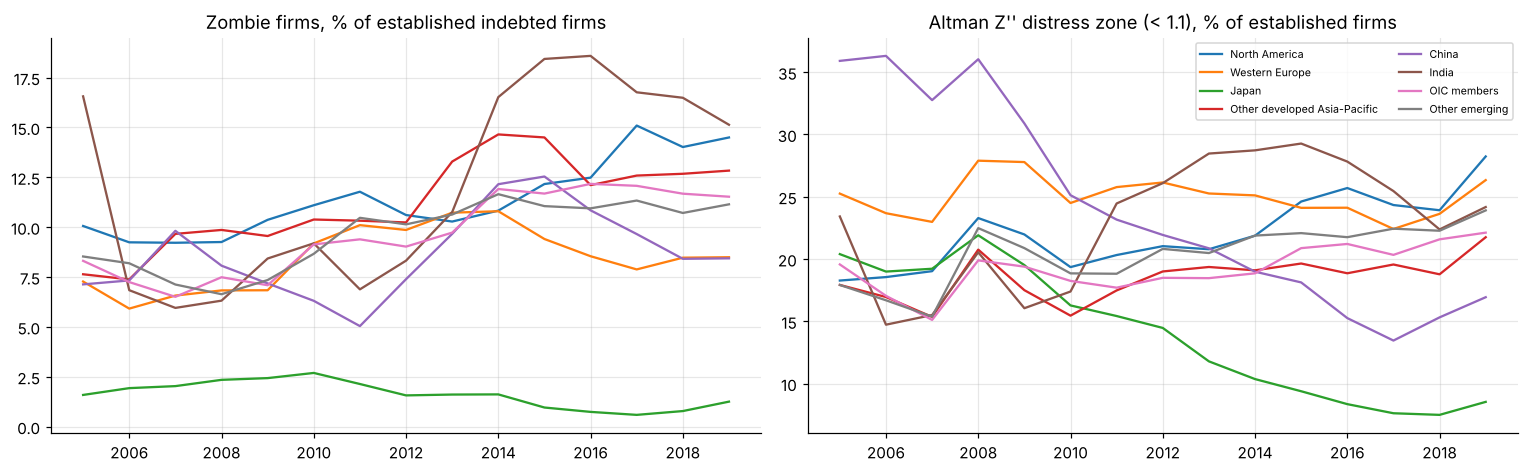

,zombie % 2008,zombie % 2019,distress % 2008,distress % 2019
region,,,,
North America,9.3,14.5,23.3,28.2
Western Europe,6.8,8.5,27.9,26.3
Japan,2.3,1.3,21.9,8.5
Other developed Asia-Pacific,9.9,12.8,20.8,21.8
China,8.1,8.4,36.0,16.9
India,6.3,15.1,20.5,24.2
OIC members,7.5,11.5,19.9,22.1
Other emerging,6.6,11.1,22.5,23.9


In [3]:
ty = p[(p.fyear <= 2019) & has_debt & p.established].groupby(["fyear", "region"])["zombie"].mean().unstack()[REG_ORDER] * 100
ty = ty.loc[2002:]                                                   # three years of history are needed
dz = p[(p.fyear <= 2019) & p.established].groupby(["fyear", "region"])["distress"].mean().unstack()[REG_ORDER] * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ty.plot(ax=ax[0], legend=False); ax[0].set_title("Zombie firms, % of established indebted firms")
dz.plot(ax=ax[1]); ax[1].set_title("Altman Z'' distress zone (< 1.1), % of established firms"); ax[1].legend(fontsize=7, ncol=2); int_years(*ax)
plt.tight_layout(); plt.savefig(IMG / "zombies_distress_trends.png", bbox_inches="tight"); plt.show()
ty = ty.loc[2008:]                                                   # five years of history needed for "established"
pd.DataFrame({"zombie % 2008": ty.loc[2008], "zombie % 2019": ty.loc[2019], "distress % 2008": dz.loc[2008], "distress % 2019": dz.loc[2019]}).round(1)

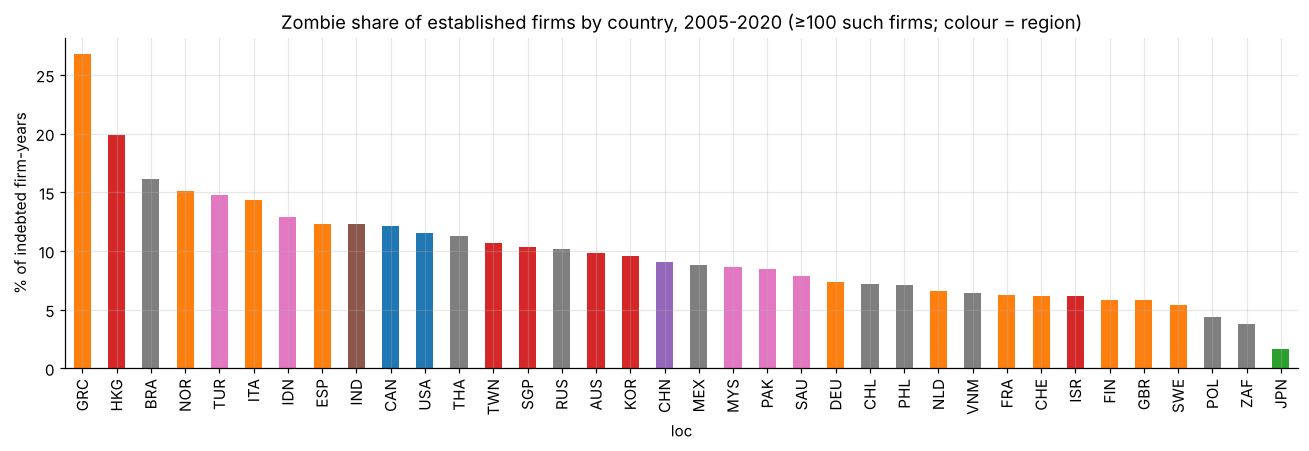

,firms,zombie,distress %,region
loc,,,,
GRC,176,26.8,42.8,Western Europe
HKG,876,19.9,15.6,Other developed Asia-Pacific
BRA,264,16.2,25.4,Other emerging
NOR,193,15.1,28.7,Western Europe
TUR,189,14.7,21.8,OIC members
ITA,258,14.3,33.0,Western Europe
IDN,296,12.9,23.2,OIC members
ESP,122,12.3,38.6,Western Europe
IND,1251,12.3,23.5,India


In [4]:
cz = p[has_debt & p.established].groupby("loc").agg(firms=("gvkey", "nunique"), zombie=("zombie", "mean"))
cz = cz[(cz.firms >= 100)].assign(zombie=lambda x: 100 * x.zombie)
cz["distress %"] = 100 * p[p.established].groupby("loc")["distress"].mean().reindex(cz.index)
cz["region"] = p.groupby("loc")["region"].first().reindex(cz.index)
cz = cz.sort_values("zombie", ascending=False)
cz.round(1).to_csv(DATA / "zombie_distress_by_country.csv")
fig, ax = plt.subplots(figsize=(12, 4.2)); cz["zombie"].plot.bar(ax=ax, color=[f"C{REG_ORDER.index(r_)}" for r_ in cz.region])
ax.set_ylabel("% of indebted firm-years"); ax.set_title("Zombie share of established firms by country, 2005-2020 (≥100 such firms; colour = region)")
plt.tight_layout(); plt.savefig(IMG / "zombies_by_country.png", bbox_inches="tight"); plt.show()
cz.head(12).round(1)

### What happens to zombies next?
For every established firm that becomes a zombie, follow it for three years: does it recover (coverage back above 1), stay a zombie, or leave the database (delisting, merger or failure)?

In [5]:
d = p[(has_debt | p.zombie) & p.established][["gvkey", "fyear", "zombie_est", "interest_cover", "region"]].sort_values(["gvkey", "fyear"])
d["first"] = d["zombie_est"] & ~d.groupby("gvkey")["zombie_est"].shift(1, fill_value=False)
ent = d[d["first"] & (d.fyear <= 2016)]
last = p.groupby("gvkey")["fyear"].max()
cover = p.set_index(["gvkey", "fyear"])["interest_cover"]
def outcome(r_):
    k = (r_.gvkey, r_.fyear + 3)
    if last[r_.gvkey] < r_.fyear + 3: return "left the database"
    c3 = cover.get(k, np.nan)
    if pd.isna(c3): return "no debt / missing"
    return "recovered (cover ≥ 1)" if c3 >= 1 else "still loss-making on interest"
ent = ent.assign(outcome=[outcome(r_) for r_ in ent.itertuples()])
o = (100 * pd.crosstab(ent.region, ent.outcome, normalize="index")).reindex(REG_ORDER).round(1)
o["new zombies"] = ent.groupby("region").size().reindex(REG_ORDER)
o

outcome,left the database,no debt / missing,recovered (cover ≥ 1),still loss-making on interest,new zombies
region,,,,,
North America,28.3,3.5,25.2,43.0,1214
Western Europe,21.3,2.3,26.1,50.4,828
Japan,15.4,3.5,50.2,30.8,227
Other developed Asia-Pacific,10.4,5.7,29.9,54.0,1096
China,5.5,6.9,37.7,49.9,677
India,11.3,2.0,24.3,62.3,345
OIC members,6.9,4.3,32.7,56.2,349
Other emerging,12.3,4.1,31.3,52.3,514


## Findings
* **Zombie firms are a real but uneven phenomenon.** Among established indebted firms (at least USD 100m of assets and five years of history), the share whose operating income has failed to cover interest for three straight years is 12% in North America, India and other developed Asia-Pacific, 10% in OIC and other emerging markets, 9% in China, 8% in Western Europe and only 1.6% in Japan. The broad definition, which includes small and young firms, roughly doubles the North American figure (19%) because many US and Canadian small caps are loss-making by design (biotech, technology, mining).
* **The share has risen since the financial crisis:** from 9% to 15% in North America, 6% to 15% in India, 8% to 12% in OIC countries and 7% to 11% in other emerging markets between 2008 and 2019. Japan is the exception (2.3% to 1.3%), after its 1990s clean-up.
* **Country hot spots:** Greece (27% of established indebted firms), Hong Kong (20%), Brazil (16%), Norway (15%, oil services after 2014), Turkey and Italy (14-15%).
* **Zombie status is persistent.** Three years after becoming a zombie, only 24-38% of firms have recovered in most regions (50% in Japan), around half are still not covering interest, and 21-28% of North American and European ones have left the database through delisting, acquisition or failure. Lenders and investors should treat a third year of coverage below 1 as a structural condition, not a cycle.
* **Altman Z'' distress shares tell a similar story.** About 22-25% of established firms are in the distress zone in North America, Europe and India, against 9-14% in Japan. Chinese distress fell from 36% in 2008 to 17% in 2019 as firms deleveraged.
* **Use:** these screens are the building blocks of a credit-portfolio early-warning system or a country risk dashboard. The code applies them to any loan book or supplier list with the same accounting fields.